<a href="https://colab.research.google.com/github/Angela-Benedict/ds2002-fa26/blob/main/notebooks/walmart-hurricane-project/Walmart%20Midterm%20Submission.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Salt Squared Midterm Submission**
##**Group Members:**
### Noor Imat, Angela Benedict, Aubin Barcheck, and Nico Roppatte

# Cleaning

**Decision Log**

# Weather Join

Source: Open-Meteo Historical Weather API, https://archive-api.open-meteo.com/v1/archive (Orlando, Sept 2024).

In [ ]:
import pandas as pd
import numpy as np
import requests
import time

transactions = pd.read_csv(
    "https://raw.githubusercontent.com/Angela-Benedict/ds2002-fa26/refs/heads/main/notebooks/walmart-hurricane-project/data/walmart_transactions.csv"
)

# messy timestamp formats before cleaning
formats = transactions["timestamp"].fillna("MISSING").str.replace(r"\d", "9", regex=True)
display(formats.value_counts())

def prepare_sales_for_weather_join(sales_df, timestamp_col):
    sales = sales_df.copy()

    before = len(sales)
    sales = sales.drop_duplicates()
    print("Duplicate rows removed:", before - len(sales))

    sales[timestamp_col] = pd.to_datetime(sales[timestamp_col], format="mixed", errors="coerce")
    sales["date"] = sales[timestamp_col].dt.normalize()

    print("Rows:", len(sales))
    print("Missing dates:", sales["date"].isna().sum())
    return sales

sales_prepared = prepare_sales_for_weather_join(transactions, "timestamp")

daily_sales = (
    sales_prepared
    .dropna(subset=["date"])
    .groupby("date")
    .size()
    .reset_index(name="orders")
)
print("Days of sales:", len(daily_sales))

BASE = "https://archive-api.open-meteo.com/v1/archive"
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start,
        "end_date": end,
        "daily": "precipitation_sum,windspeed_10m_max",
        "hourly": "surface_pressure",
        "timezone": "America/New_York",
    }
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=30)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
        data = r.json()

        frame = pd.DataFrame(data["daily"]).rename(columns={"time": "date"})
        frame["date"] = pd.to_datetime(frame["date"])

        # hourly pressure -> daily mean
        pressure = pd.DataFrame(data["hourly"])
        pressure["date"] = pd.to_datetime(pressure["time"]).dt.normalize()
        daily_pressure = (
            pressure.groupby("date", as_index=False)["surface_pressure"].mean()
            .rename(columns={"surface_pressure": "surface_pressure_mean"})
        )
        frame = frame.merge(daily_pressure, on="date", how="left")
        frame["source"] = "open-meteo"
        return frame

weather_live = daily_weather("2024-09-01", "2024-09-30")
print("source:", weather_live["source"].iloc[0])

# timezone check: UTC days vs Eastern days
params = {
    "latitude": 28.54, "longitude": -81.38,
    "start_date": "2024-09-01", "end_date": "2024-09-30",
    "hourly": "windspeed_10m",
    "timezone": "GMT",
}
r = requests.get(BASE, params=params, timeout=30)
r.raise_for_status()
hourly = pd.DataFrame(r.json()["hourly"])
hourly["time_utc"] = pd.to_datetime(hourly["time"]).dt.tz_localize("UTC")
hourly["time_et"] = hourly["time_utc"].dt.tz_convert("America/New_York")
hourly["date_utc"] = hourly["time_utc"].dt.tz_localize(None).dt.normalize()
hourly["date_et"] = hourly["time_et"].dt.tz_localize(None).dt.normalize()
print("Hours that fall on a different date in UTC vs Eastern:",
      (hourly["date_utc"] != hourly["date_et"]).sum(), "of", len(hourly))
compare = pd.DataFrame({
    "max wind, UTC days": hourly.groupby("date_utc")["windspeed_10m"].max(),
    "max wind, Eastern days": hourly.groupby("date_et")["windspeed_10m"].max(),
}).loc["2024-09-24":"2024-09-28"]
display(compare)

# validated left join
sales_weather = daily_sales.merge(weather_live, on="date", how="left")
print("Sales rows before join:", len(daily_sales))
print("Rows after join:", len(sales_weather))
print("Missing weather rows:", sales_weather["precipitation_sum"].isna().sum())
assert len(sales_weather) == len(daily_sales), "join changed the row count"
assert sales_weather["orders"].sum() == daily_sales["orders"].sum(), "join changed total orders"
print("All join checks passed")

weather_live.to_csv("weather_orlando_sept2024.csv", index=False)
sales_weather.to_csv("sales_weather_daily.csv", index=False)

,count
timestamp,
9999-99-99 99:99:99,12179
99/99/9999 99:99,5031
99-Sep-9999 99:99,2546
9999-99-99T99:99:99,2511
99-99-9999 99:99:99,2409
MISSING,886


Duplicate rows removed: 30
Rows: 25532
Missing dates: 884
Days of sales: 30
source: open-meteo
Hours that fall on a different date in UTC vs Eastern: 120 of 720


,"max wind, UTC days","max wind, Eastern days"
2024-09-24,17.7,17.7
2024-09-25,27.2,27.2
2024-09-26,46.1,48.8
2024-09-27,48.8,45.1
2024-09-28,19.8,19.8


Sales rows before join: 30
Rows after join: 30
Missing weather rows: 0
All join checks passed


**Timezone handling:** Open-Meteo uses UTC as its default timezone, while the sales data is in Eastern time (UTC-4 in September). In UTC, the last four hours of each Eastern day belong to the next day, and therefore, 120 out of 720 hours have the wrong date. In order to avoid this problem, the weather API request has been made by setting timezone=America/New_York, making each day the same midnight to midnight as that of the sales data. Without the timezone conversion, the highest wind speed (48.8 km/h) would occur on September 27 instead of September 26, the day of landfall.

# Questions and Visualizations

## **Question 1:**

**Markdown Explanation of What We Did**

**Which product categories experienced the greatest sales surge in the 7 days before hurricane landfall compared to the prior baseline period? Quantify the percentage increase and visualize the daily trend for the top 5 categories.**

## **Question 2:**

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/Angela-Benedict/ds2002-fa26/main/notebooks/walmart-hurricane-project/data/walmart_transactions.csv"
sales = pd.read_csv(url).drop_duplicates()
sales["quantity"] = pd.to_numeric(sales["quantity"], errors="coerce")
sales["name_clean"] = sales["product_name"].str.strip().str.lower()

print("Distinct SKUs before:", sales["sku"].nunique())
print("Distinct product names before:", sales["product_name"].nunique())

# skus sold under the same name are the same product
parent = {sku: sku for sku in sales["sku"].unique()}

def find(sku):
    while parent[sku] != sku:
        sku = parent[sku]
    return sku

for name, skus in sales.groupby("name_clean")["sku"].unique().items():
    for sku in skus[1:]:
        parent[find(sku)] = find(skus[0])

sales["group"] = sales["sku"].map(find)
canonical = sales.groupby("group")["product_name"].agg(lambda x: x.str.strip().value_counts().index[0])
sales["product_canonical"] = sales["group"].map(canonical)

print("Canonical products after:", sales["product_canonical"].nunique())

families = sales.groupby("product_canonical")["sku"].unique()
largest = families.str.len().idxmax()
print("Largest family:", largest)
print("SKUs in largest family:", list(families[largest]))

units_before = sales.groupby("sku")["quantity"].sum().sum()
units_after = sales.groupby("product_canonical")["quantity"].sum().sum()
assert units_before == units_after
print("Unit totals before and after:", units_before, units_after)

sales.groupby("product_canonical")["sku"].nunique().sort_values(ascending=False)

Distinct SKUs before: 45
Distinct product names before: 63
Canonical products after: 20
Largest family: Pop-Tarts Strawberry
SKUs in largest family: ['PT_STRAWBERRY', 'SKU#459812', 'PT-12', 'POPTART-STRAW']
Unit totals before and after: 49343 49343


,sku
product_canonical,
Pop-Tarts Strawberry,4
AA Batteries 4-Pack,3
Bottled Water 24-Pack,3
Board Game - Monopoly,3
BABY FORMULA,2
CANDLES - EMERGENCY,2
First-Aid Kit,2
Diapers Size 3,2
LED Flashlight,2


In [2]:
# Find all Pop-Tart sales
poptarts = sales[
    sales['product_canonical'].str.contains('pop.?tart', case=False, na=False)
].copy()

# Convert timestamp into a date
poptarts['date'] = pd.to_datetime(
    poptarts['timestamp'],
    format='mixed',
    dayfirst=True
).dt.date

# Calculate total Pop-Tart units sold each day
daily_sales = (
    poptarts.groupby('date')['quantity']
    .sum()
    .reset_index(name='total_poptarts_sold')
)

print("Daily Pop-Tart Sales Volume:")
display(daily_sales)

# Calculate average daily sales volume
print("Average Pop-Tarts sold daily:", daily_sales['total_poptarts_sold'].sum()/daily_sales['date'].nunique())

Daily Pop-Tart Sales Volume:


,date,total_poptarts_sold
0,2024-01-09,26
1,2024-02-09,20
2,2024-03-09,20
3,2024-04-09,22
4,2024-05-09,20
5,2024-06-09,15
6,2024-07-09,28
7,2024-08-09,32
8,2024-09-01,54
9,2024-09-02,46


Average Pop-Tarts sold daily: 121.58536585365853


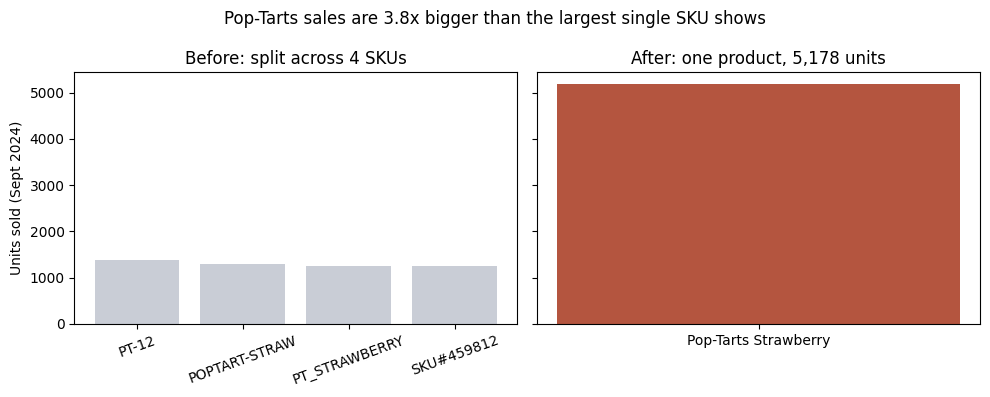

Largest single SKU: 1377 | Consolidated: 5178


In [3]:
import matplotlib.pyplot as plt

pop = sales[sales["product_canonical"] == largest]
before = pop.groupby("sku")["quantity"].sum().sort_values(ascending=False)
after = before.sum()

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
axes[0].bar(before.index, before.values, color="#c9cdd6")
axes[0].set_title("Before: split across 4 SKUs")
axes[0].set_ylabel("Units sold (Sept 2024)")
axes[0].tick_params(axis="x", rotation=20)
axes[1].bar([largest], [after], color="#b4553f")
axes[1].set_title(f"After: one product, {after:,.0f} units")
fig.suptitle(f"Pop-Tarts sales are {after / before.max():.1f}x bigger than the largest single SKU shows")
plt.tight_layout()
plt.show()

print("Largest single SKU:", before.max(), "| Consolidated:", after)

**Markdown Explanation of What We Did**

**After standardizing all Pop-Tart SKU variants into a single product, what is the true daily sales volume? How does the uncleaned (fragmented) view compare to the cleaned (consolidated) view? What business decisions would differ between the two views?**

**Answer:** We started out with 45 SKUs and 63 product names, but ended up consolidating to 20 products without any change in units (49,343 before consolidation and after consolidation). Looking at average daily poptart sales volume, we can see about 121 are sold a day. The biggest product family is Pop-Tarts Strawberry (4 SKUs), where the biggest SKU has only 1,377 units. Nevertheless, the consolidated product had 5,178 units, so the fragmented view understates demand by 3.8 times. Business decisions could differ if you take into account package size which we ignored here by consolidating. Maybe customers only will buy a certain size box.

## **Question 3:**

,orders,precipitation_sum,windspeed_10m_max,surface_pressure_mean
orders,1.000000,-0.249757,0.391469,-0.262693
precipitation_sum,-0.249757,1.000000,-0.041890,0.238997
windspeed_10m_max,0.391469,-0.041890,1.000000,-0.701757
surface_pressure_mean,-0.262693,0.238997,-0.701757,1.000000


,date,orders,precipitation_sum,windspeed_10m_max,surface_pressure_mean,source
20,2024-09-21,1313,0.4,19.9,1008.025000,open-meteo
21,2024-09-22,1367,2.2,17.9,1008.137500,open-meteo
22,2024-09-23,1374,1.3,16.6,1008.700000,open-meteo
23,2024-09-24,1968,0.3,17.7,1009.008333,open-meteo
24,2024-09-25,2007,6.4,27.2,1007.233333,open-meteo
25,2024-09-26,1139,15.2,48.8,999.675000,open-meteo
26,2024-09-27,851,2.5,40.1,1002.237500,open-meteo
27,2024-09-28,879,18.0,19.8,1007.766667,open-meteo


,lag,correlation,n_pairs
0,-14,-0.179280,16
1,-13,-0.273784,17
2,-12,-0.200816,18
3,-11,0.107861,19
4,-10,0.480341,20
5,-9,0.157871,21
6,-8,0.056510,22
7,-7,0.056579,23
8,-6,0.135153,24
9,-5,0.293070,25


Strongest lag: -2
Correlation: 0.823 on 28 pairs


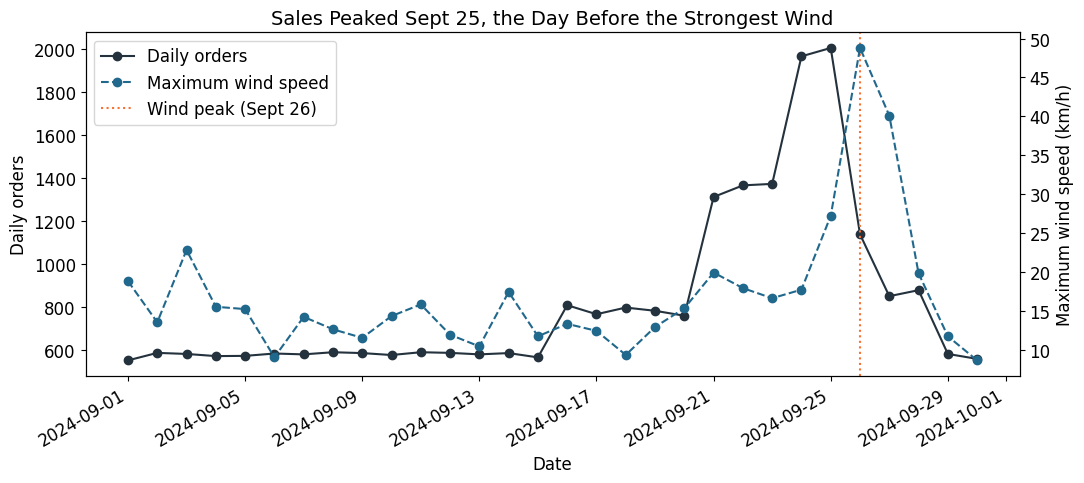

,precipitation_corr,wind_corr,pressure_corr
category_clean,,,
Alcohol,-0.255,0.372,-0.220
Baby,-0.304,0.214,-0.162
Breakfast,-0.239,0.403,-0.278
Electronics,-0.242,0.367,-0.229
Emergency,-0.248,0.424,-0.301
Entertainment,-0.214,0.426,-0.293
Grocery,-0.278,0.296,-0.172
Health,-0.253,0.365,-0.258
Household,-0.224,0.393,-0.252


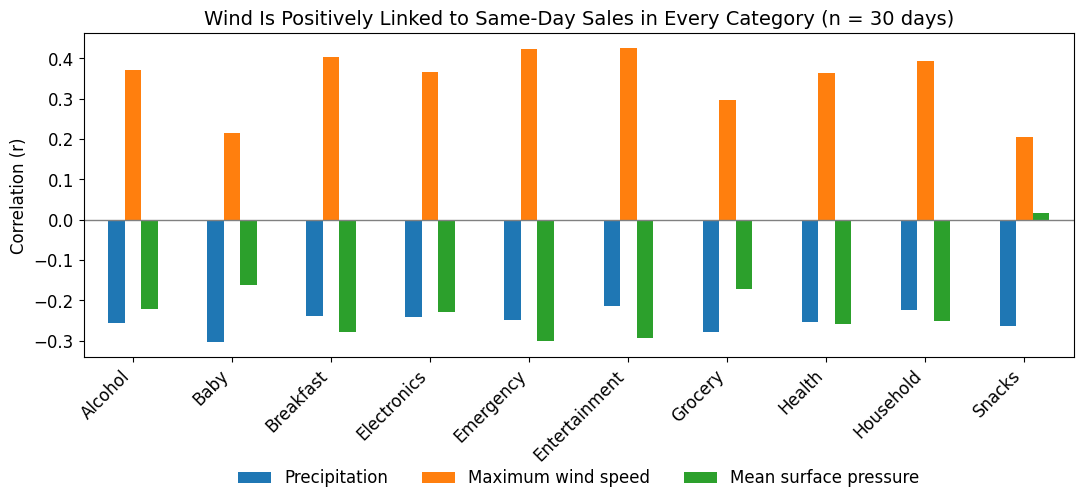

In [ ]:
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "axes.titlesize": 14})

display(sales_weather[["orders", "precipitation_sum", "windspeed_10m_max", "surface_pressure_mean"]].corr())
display(sales_weather[(sales_weather["date"] >= "2024-09-21") & (sales_weather["date"] <= "2024-09-28")])

lag_results = []
for lag in range(-14, 15):
    shifted_wind = sales_weather["windspeed_10m_max"].shift(lag)
    valid_pairs = sales_weather["orders"].notna() & shifted_wind.notna()
    corr = sales_weather.loc[valid_pairs, "orders"].corr(shifted_wind[valid_pairs])
    lag_results.append({"lag": lag, "correlation": corr, "n_pairs": valid_pairs.sum()})
lag_results = pd.DataFrame(lag_results)
display(lag_results)

best_lag = lag_results.loc[lag_results["correlation"].abs().idxmax()]
print("Strongest lag:", int(best_lag["lag"]))
print("Correlation:", round(best_lag["correlation"], 3), "on", int(best_lag["n_pairs"]), "pairs")

fig, ax1 = plt.subplots(figsize=(11, 5))
sales_line = ax1.plot(sales_weather["date"], sales_weather["orders"], marker="o", color="#24323E", label="Daily orders")
ax1.set_xlabel("Date")
ax1.set_ylabel("Daily orders")
ax2 = ax1.twinx()
wind_line = ax2.plot(sales_weather["date"], sales_weather["windspeed_10m_max"], marker="o", linestyle="--",
                     color="#21688D", label="Maximum wind speed")
ax2.set_ylabel("Maximum wind speed (km/h)")
wind_peak = ax1.axvline(pd.Timestamp("2024-09-26"), color="#F67132", linestyle=":", label="Wind peak (Sept 26)")
lines = sales_line + wind_line + [wind_peak]
ax1.legend(lines, [l.get_label() for l in lines], loc="upper left")
plt.title("Sales Peaked Sept 25, the Day Before the Strongest Wind")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

category_map = {
    "emergency": "Emergency", "emergency supplies": "Emergency",
    "groceries": "Grocery", "grocery": "Grocery",
    "electronics": "Electronics",
    "entertainment": "Entertainment", "games & entertainment": "Entertainment",
    "household": "Household", "household essentials": "Household",
    "baby": "Baby", "baby products": "Baby",
    "breakfast": "Breakfast", "breakfast foods": "Breakfast",
    "alcohol": "Alcohol", "alcoholic beverages": "Alcohol",
    "snacks": "Snacks",
    "health": "Health", "health & wellness": "Health",
}
sales_prepared["category_clean"] = sales_prepared["category"].str.strip().str.lower().map(category_map)

daily_category_sales = (
    sales_prepared.dropna(subset=["date", "category_clean"])
    .groupby(["date", "category_clean"]).size()
    .reset_index(name="orders")
)
category_weather = daily_category_sales.merge(weather_live, on="date", how="left")

category_correlations = (
    category_weather.groupby("category_clean")
    .apply(lambda x: pd.Series({
        "precipitation_corr": x["orders"].corr(x["precipitation_sum"]),
        "wind_corr": x["orders"].corr(x["windspeed_10m_max"]),
        "pressure_corr": x["orders"].corr(x["surface_pressure_mean"]),
    }), include_groups=False)
    .round(3)
)
display(category_correlations)

ax = category_correlations.rename(columns={
    "precipitation_corr": "Precipitation",
    "wind_corr": "Maximum wind speed",
    "pressure_corr": "Mean surface pressure",
}).plot(kind="bar", figsize=(11, 5.5))
ax.axhline(0, color="gray", linewidth=1)
ax.set_title("Wind Is Positively Linked to Same-Day Sales in Every Category (n = 30 days)")
ax.set_xlabel("")
ax.set_ylabel("Correlation (r)")
plt.xticks(rotation=45, ha="right")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

**Markdown Explanation of What We Did**

The order count per day (all stores with duplicates removed) was linked to the weather of Orlando per day using the Open-Meteo API via a left join on dates, so no sales day was dropped. The correlation was computed between the orders and wind speed, precipitation, and surface pressure for total orders as well as the 10 different categories on the same day. In order to investigate a lag effect, wind speed was lagged by -14 to +14 days, recording the correlation and number of overlapping days for each shift.

**Using weather data pulled from your chosen free API, how do specific weather indicators (wind speed, precipitation, barometric pressure) correlate with daily sales volume across categories? Is there a detectable lag between weather severity escalation and purchasing spikes?**

**Answer:**  On the same day, there was a moderate positive correlation between maximum wind speed and sales (r = 0.391, n = 30), but there was a weak negative correlation between sales and precipitation (r = -0.250, n = 30) and mean surface pressure (r = -0.263, n = 30). There was a high correlation between low pressure and high winds (r = -0.702). The category level correlations revealed the same trend for all categories, with positive wind correlations ranging from 0.206 (Snacks) to 0.426 (Entertainment). The correlation coefficient showed the highest value with lag -2 days (r = 0.823, n = 28 pairs), which indicates that increased sales occurred two days before increased wind speeds. The peak of sales was observed from September 24 to 25, with 1,968 and 2,007 orders respectively, whereas the peak of wind speed was recorded on September 26, which amounted to 48.8 km/h, i.e., the day when the landfall occurred. Since it’s only one month and one weather location, this result should be considered as just a time relationship.

## **Question 4:**

**Markdown Explanation of What We Did**

**Do all Florida store locations experience the same surge patterns, or do stores closer to the predicted hurricane path show earlier and larger spikes? Identify any stores that appear to be outliers.**

## **Question 5:**

In [ ]:
import pandas as pd
import sqlite3
import requests

base = "https://raw.githubusercontent.com/Angela-Benedict/ds2002-fa26/main/notebooks/walmart-hurricane-project/data/"

# download the database file so sqlite3 can open it
r = requests.get(base + "inventory_and_sales.db", timeout=30)
r.raise_for_status()
with open("inventory_and_sales.db", "wb") as f:
    f.write(r.content)

conn = sqlite3.connect("inventory_and_sales.db")
db_sales = pd.read_sql_query("SELECT * FROM daily_sales_summary", conn)
inventory = pd.read_sql_query("SELECT * FROM inventory_levels", conn)

db_sales["date"] = pd.to_datetime(db_sales["date"], format="mixed")
inventory["date"] = pd.to_datetime(inventory["date"], format="mixed")

tx = pd.read_csv(base + "walmart_transactions.csv").drop_duplicates()
tx["date"] = pd.to_datetime(tx["timestamp"], format="mixed", errors="coerce").dt.normalize()
tx["quantity"] = pd.to_numeric(tx["quantity"], errors="coerce")

# what is actually inside "Entertainment"?
ent = tx[tx["category"].str.strip().str.lower().isin(["entertainment", "games & entertainment"])]
print(ent.groupby(["sku", "product_name"]).size())

# consolidate the SKUs into the two real products
game_map = {
    "BG-MONO": "Board games", "GAME-MONO": "Board games", "MONOPOLY-01": "Board games",
    "CARDS-01": "Playing cards", "PLAYCARD-STD": "Playing cards",
}
tx["game_product"] = tx["sku"].map(game_map)
inventory["game_product"] = inventory["sku"].map(game_map)

print("\nSKUs per product:")
print(tx.dropna(subset=["game_product"]).groupby("game_product")["sku"].unique())

sku           product_name          
BG-MONO       Board Game - Monopoly     133
              MONOPOLY                  135
              Monopoly Board Game       164
CARDS-01      PLAYING CARDS             191
              Playing Cards             203
              Standard Playing Cards    193
GAME-MONO     Board Game - Monopoly     171
              MONOPOLY                  152
              Monopoly Board Game       143
MONOPOLY-01   Board Game - Monopoly     155
              MONOPOLY                  144
              Monopoly Board Game       142
PLAYCARD-STD  PLAYING CARDS             201
              Playing Cards             201
              Standard Playing Cards    210
dtype: int64

SKUs per product:
game_product
Board games      [BG-MONO, MONOPOLY-01, GAME-MONO]
Playing cards             [CARDS-01, PLAYCARD-STD]
Name: sku, dtype: object


In [ ]:
baseline = ("2024-09-08", "2024-09-15")
surge = ("2024-09-19", "2024-09-25")

daily_cat = db_sales.groupby(["date", "category"])["total_units"].sum().unstack()

base_avg = daily_cat.loc[baseline[0]:baseline[1]].mean()
surge_avg = daily_cat.loc[surge[0]:surge[1]].mean()
peak_day = daily_cat.loc[surge[0]:surge[1]].idxmax()
peak_val = daily_cat.loc[surge[0]:surge[1]].max()

check = pd.DataFrame({
    "week_increase_%": ((surge_avg / base_avg - 1) * 100).round(1),
    "peak_day": peak_day.dt.strftime("%b %d"),
    "peak_day_increase_%": ((peak_val / base_avg - 1) * 100).round(1),
}).sort_values("week_increase_%", ascending=False)

check

,week_increase_%,peak_day,peak_day_increase_%
category,,,
Breakfast,229.5,Sep 25,455.4
Emergency,182.6,Sep 25,311.7
Entertainment,135.3,Sep 24,256.5
Health,117.2,Sep 24,217.5
Alcohol,107.5,Sep 24,191.2
Electronics,94.7,Sep 25,202.2
Household,93.7,Sep 24,180.8
Baby,58.6,Sep 25,133.6
Grocery,55.2,Sep 24,106.3


In [ ]:
games = tx[tx["game_product"].notna() & (tx["quantity"] > 0)]
daily_games = (
    games.groupby(["date", "game_product"])["quantity"].sum()
    .unstack(fill_value=0)
)
daily_games["Entertainment total"] = daily_games.sum(axis=1)

game_base = daily_games.loc[baseline[0]:baseline[1]].mean()
game_surge = daily_games.loc[surge[0]:surge[1]].mean()

game_check = pd.DataFrame({
    "baseline_per_day": game_base.round(1),
    "surge_per_day": game_surge.round(1),
    "week_increase_%": ((game_surge / game_base - 1) * 100).round(1),
})
game_check

,baseline_per_day,surge_per_day,week_increase_%
game_product,,,
Board games,42.9,111.4,159.9
Playing cards,59.1,117.1,98.1
Entertainment total,102.0,228.6,124.1


In [ ]:
# does inventory drop when sales go up? (real sales should use up stock)
inventory["product"] = inventory["game_product"]
inventory.loc[inventory["sku"].isin(["PT-12", "POPTART-STRAW", "PT_STRAWBERRY", "SKU#459812"]), "product"] = "Pop-Tarts (for comparison)"

stock = (
    inventory.dropna(subset=["product"])
    .groupby(["date", "product"])["units_on_hand"].mean()
    .unstack()
)

stock_check = pd.DataFrame({
    "mid_Sept_stock (Sept 13-18)": stock.loc["2024-09-13":"2024-09-18"].mean().round(0),
    "pre_landfall_stock (Sept 22-25)": stock.loc["2024-09-22":"2024-09-25"].mean().round(0),
})
display(stock_check)

# SKUs in inventory that never show up in sales
orphan_skus = sorted(set(inventory["sku"]) - set(tx["sku"]))
print("Inventory SKUs with no sales records:", orphan_skus)

,mid_Sept_stock (Sept 13-18),pre_landfall_stock (Sept 22-25)
product,,
Board games,128.0,36.0
Playing cards,127.0,27.0
Pop-Tarts (for comparison),123.0,37.0


Inventory SKUs with no sales records: ['LEGACY-PT', 'MISC-001', 'OLD-BATT-50', 'UNKNOWN-99']


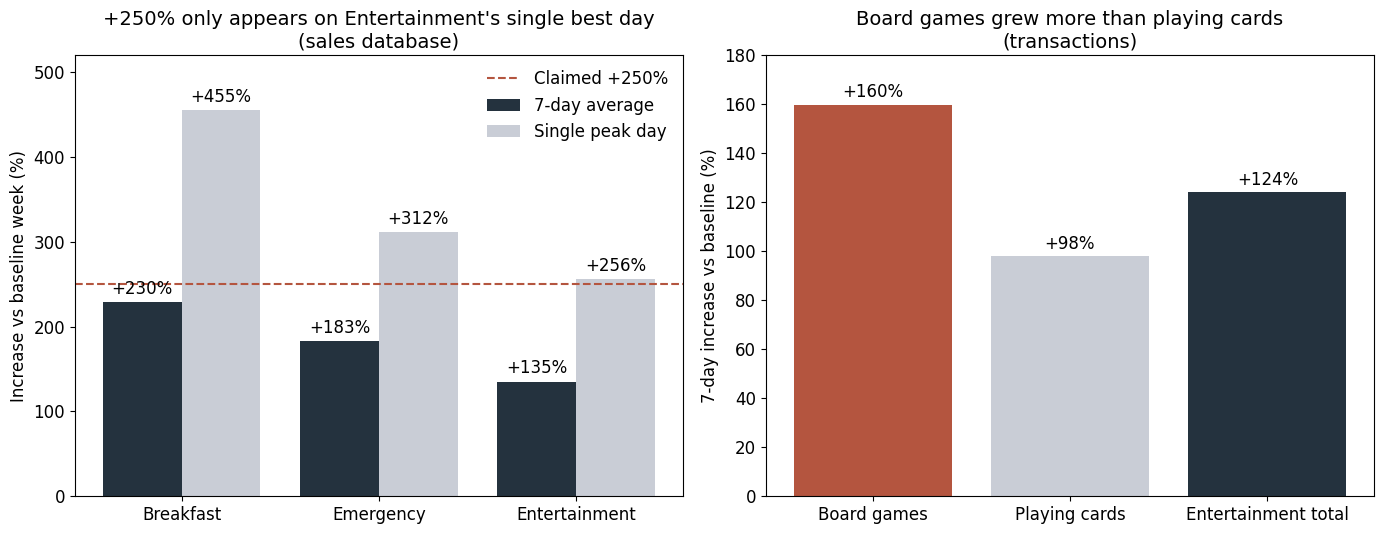

In [ ]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# left: the +250% only shows up on the single peak day
top = check.loc[["Breakfast", "Emergency", "Entertainment"]]
x = range(len(top))
week_bars = ax1.bar([i - 0.2 for i in x], top["week_increase_%"], width=0.4, label="7-day average", color="#24323E")
peak_bars = ax1.bar([i + 0.2 for i in x], top["peak_day_increase_%"], width=0.4, label="Single peak day", color="#c9cdd6")
ax1.bar_label(week_bars, labels=[f"+{v:.0f}%" for v in top["week_increase_%"]], padding=3)
ax1.bar_label(peak_bars, labels=[f"+{v:.0f}%" for v in top["peak_day_increase_%"]], padding=3)
ax1.axhline(250, color="#b4553f", linestyle="--", label="Claimed +250%")
ax1.set_xticks(list(x))
ax1.set_xticklabels(top.index)
ax1.set_ylim(0, 520)
ax1.set_ylabel("Increase vs baseline week (%)")
ax1.set_title("+250% only appears on Entertainment's single best day\n(sales database)")
ax1.legend(frameon=False, loc="upper right")

# right: Entertainment mixes two products that grew differently
parts = game_check.loc[["Board games", "Playing cards", "Entertainment total"], "week_increase_%"]
ax2.bar(parts.index, parts.values, color=["#b4553f", "#c9cdd6", "#24323E"])
for i, v in enumerate(parts.values):
    ax2.text(i, v + 3, f"+{v:.0f}%", ha="center")
ax2.set_ylim(0, 180)
ax2.set_ylabel("7-day increase vs baseline (%)")
ax2.set_title("Board games grew more than playing cards\n(transactions)")

plt.tight_layout()
plt.show()

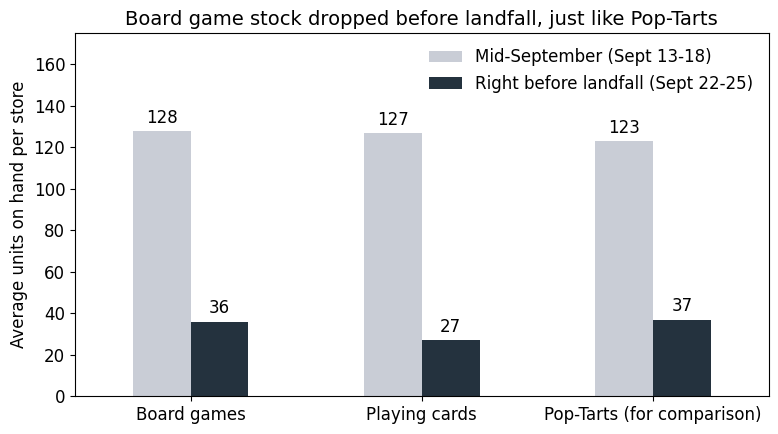

In [ ]:
ax = stock_check.plot(kind="bar", figsize=(8, 4.5), color=["#c9cdd6", "#24323E"], rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)
ax.set_ylim(0, 175)
ax.set_ylabel("Average units on hand per store")
ax.set_xlabel("")
ax.set_title("Board game stock dropped before landfall, just like Pop-Tarts")
ax.legend(["Mid-September (Sept 13-18)", "Right before landfall (Sept 22-25)"],
          frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

**Markdown Explanation of What We Did**

We imported the daily_sales_summary and inventory_levels tables from the SQLite database and the transactions file as well. First, we investigated what is present in the Entertainment category and found out there are just two items within: Monopoly (3 SKUs) and playing cards (2 SKUs); therefore, we grouped all these SKUs. Then we analyzed the seven-day period before the storm (Sept 19-25) vs. the baseline week (Sept 8-15) and the single peak day as well. Furthermore, we divided the Entertainment category into board games and playing cards, investigated if the store inventory decreased during the spike and investigated SKUs not present in sales but present in the inventory table.

**The board games/entertainment category shows a +250% sales increase. Using the SQLite inventory and sales database, investigate whether this is a genuine demand signal or a data artifact (e.g., SKU miscoding, category lumping, inventory reporting lag). Present your evidence and make a recommendation: should Walmart stock extra board games for the next storm?**

**Answer:** The board game spike is a reality, but +250% is overstated. Entertainment only reached +256% on a single day (Sept 24). On average over 7 days before the storm, entertainment grew by +135%, which is lower compared to Breakfast (+230%) and Emergency Supplies (+183%). This category includes two products: board games increased by +160% while playing cards increased by +98%. The spike seems to be driven by real consumer demand and not by mistake since the board game stock fell from ~128 to 36 units per store before the storm, just like Pop-Tarts (123 to 37). 4 SKUs were found in the inventory that are never part of any sale (UNKNOWN-99, MISC-001, LEGACY-PT, OLD-BATT-50); however, there is no link between those and board games. Recommendation for Walmart: it is advised to stock more board games for the next storm, planning for about double normal sales instead of 3.5 times, but not taking truck space from Breakfast and Emergency Supplies, which increased more.

**Next steps:** (1) Prior to the next storm, stock about twice the usual amount of board games for the week before the storm’s landfall, reserving any extra truck capacity only after Breakfast and Emergency Supply SKUs have been filled. (2) It would be better to consolidate the Monopoly SKUs into one item and the Playing Card SKUs into one item, so each shows up as a single product in future reports. (3) Storm surges are to be counted in seven-day averages and not just peak days, and board games have to be considered separate from playing cards. (4) Check out the four SKUs not appearing in sales.


# Reflection Questions

## **Question 1: Data Quality Impact**
**Describe a specific data quality issue you encountered in the supplied data. How did your cleaning decision change the outcome of your analysis? What would have happened if you had not caught it?**

## **Question 2: ETL Trade-offs**
**You made choices about how to standardize SKUs, handle missing timestamps, and join weather data. Pick one decision and explain: what alternative approach could you have taken, and how might it have changed your results?**

A decision we had to make was how to merge the weather data with the sales data. We chose a left join based on date because it kept all the sales days, even if there was no corresponding weather data. On the other hand, an inner join would only keep the days when there was a match on both sides. In our case, all 30 days matched, so we would have gotten the same result whichever method we chose. However, if there were one day missing from the weather data, the inner join would have silently omitted that day from the analysis. That would be critical if the missing day was September 26, the landfall day. We would have lost the most important day of the entire analysis, and the plot would appear completely normal.

Another decision we made was to request the weather data in Eastern time instead of the API's default UTC. There are 120 out of the 720 hours that fall on a different date in UTC. Therefore, the wind peak would appear on September 27 instead of September 26, shifting our lag result by a day.

## **Question 3: Pipeline Trust**
**The Walmart CDO argued that the biggest risk is not the model — it is the pipeline. Based on your experience in this project, do you agree or disagree? What was the most fragile part of your data pipeline?**

We agree with the CDO. Most of the issues we faced arose due to the data pipeline and not due to the calculations. Cleaning the data made it easy for us to calculate the correlation and surge multiples. The most vulnerable part of the data pipeline was the timestamp parser. We had a sales file with five different formats for dates, but with pandas, we could read just one without format="mixed". Therefore, out of 25,562 rows, we got date information on only 2,511. There were no errors at all, and our Q1 sales figure was roughly 10 times smaller. Breakfast continued to be the top category, which made it easy to forget about this issue. The other issue was SKU fragmentation, where the Pop-Tarts brand had been fragmented into 4 SKUs, and the largest SKU had understated the demand by 3.8 times. The live weather API produced slightly different results every time, causing some variations in the correlations (e.g., 0.375 versus 0.391). Overall, the important lesson that we learned from this exercise was the need to validate row counts after each step due to silent row drops.

## **Question 4: Business vs. Data**
**For Question 5 (board games), your team had to make a recommendation with imperfect data. How did you weigh statistical evidence against business risk? Would you have decided differently with more time or more data?**

We didn’t take the +250% at face value. It only happened on one day (Sept 24), so we used the 7-day average instead, which was +135%. It was still an actual growth since the inventory proved that the board games supply fell from 128 to 36 per store prior to the storm, meaning that people were purchasing them and it wasn’t a miscalculation. In terms of business risks, the board games take up truck space that could go to goods such as Breakfast and Emergency Supplies (230% and 183% growth). Therefore, it was advised that there should be a provision of double normal board games rather than 3.5 times the normal number, only after stocking the more essential goods. Over-stocking of board games would not affect much, but lack of water or batteries could make things worse. If given more time or data, we would have checked previous hurricanes and other stores to check if the same trend exists. It is currently based on one hurricane and one month’s experience.

## **Question 5: Team Collaboration**
**How did your team divide the work? What would you do differently if you had another week? What was the most valuable skill each team member contributed?**